# HCWF benchmark demo: Ethiopia

Benchmark rainy-season **onset forecasts** against observations, as one run: build a config, check it, run a deterministic and a probabilistic benchmark, and read the results as Python objects.

Steps: 1 setup, 2 config and `hcwf.check`, 3 the onset definition, 4 runs, 5 results and figures, 6 units, caches, run folder.
Data: zarr stores of observations and of AIFS_v2, GraphCast and AIFS_ENS_v2 forecasts. Runtime: about 20 seconds on a many-core machine.

CLI equivalent of the whole notebook: `hcwf-run -p run.yaml` (the config below, as YAML).

## 1. Setup
One variable (`DATA`) points at the data; everything else is built from it.

In [1]:
%matplotlib inline
import os
from pathlib import Path

REGION = "ethiopia"

# ONE place that says where the data are: set HCWF_DEMO_DATA, or keep the repo's data/ folder
# (found by looking upward from the folder this notebook runs in). It must hold <region>/obs.zarr
# and <region>/models/<MODEL>.zarr.
DATA = Path(os.environ.get("HCWF_DEMO_DATA")
            or next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / REGION).is_dir())).expanduser()
OBS = DATA / REGION / "obs.zarr"
MODELS = DATA / REGION / "models"
print("data root:", DATA)

import copy
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import Image, display

import hcwf

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (9, 3.5)})


def show(folder, pattern, width=760):
    """Display the figure files of a run folder that match a pattern."""
    for path in sorted(Path(folder).glob(pattern)):
        print(path.name)
        display(Image(filename=path, width=width))

data root: ../../data


## 2. The run config
A run is one config: a Python dict that mirrors the YAML sections (`hcwf-run init` writes a starting YAML from your files).

* `region`: the area; supplies the box, the **day boundary** (00 UTC, labelled by start (CHIRPS v3)), the climatology years (1998-2024) and the default onset definition (`icpac`).
* `observations`, `models`: where the rain is. Variable, units, dims, members and the accumulation are **detected** from the stores and reported by `hcwf.check`.
* `evaluation`: the forecast issue dates (`start_date` to `end_date`; month and day bound the season), lead-time windows, onset tolerances (days) and the lead bins.
* `onset`: the onset definition (here the region's default, spelled out).
* `reference`: the benchmark to beat, the onset climatology. `climatology_cv: leave_one_year_out` (the default) leaves the scored year out of its own climatology, so it is not credited with knowing that year.
* `output`: what is written and where (`write=True`); by default a run folder under `runs/` next to the notebook.

In [2]:
cfg = {
    "project_name": "Ethiopia benchmark demo",
    "region": REGION,
    "observations": {"path": str(OBS)},
    "models": [
        {"name": "AIFS", "path": str(MODELS / "AIFS_v2.zarr"), "lead_label": "start"},
        {"name": "GraphCast", "path": str(MODELS / "graphcast.zarr"), "lead_label": "start"},
    ],
    "evaluation": {
        "start_date": [2015, 5, 1],   # forecasts issued 1 May - 31 Aug of each year 2015-2024
        "end_date": [2024, 8, 31],
        "verification_windows": [[1, 15], [16, 30]],   # lead days scored together
        "tolerances": [3, 5],                          # days of onset error that still count as a hit
        "max_forecast_day": 30,
        "day_bins": [[1, 5], [6, 10], [11, 15], [16, 20], [21, 25], [26, 30]],
        "probabilistic": False,                        # True: a model's members give onset probabilities
    },
    "onset": {"definition": "icpac"},
    "reference": {"climatology_cv": "leave_one_year_out"},
    "output": {"save_onsets": False},
}

`hcwf.check` resolves the config and reports the plan without running anything: every value with its **source** (`run config`, `region default`, `detected`, `default`), the datasets, the lead windows and the run folder.

In [3]:
plan = hcwf.check(cfg)
print("ok:", plan.ok, "| errors:", plan.errors)
print("warnings:", plan.warnings)
sections = plan.text().split("\n== ")
for section in sections[1:3]:   # Settings and Datasets; the rest (grids, lead windows, run folder) is in plan.text()
    for line in ("== " + section).splitlines():
        print(line[:150])

ok: True | errors: []
warnings: ['[AIFS] latitudes run north to south; HCWF flips them to south to north, nothing to set', '[GraphCast] latitudes run north to south; HCWF flips them to south to north, nothing to set', '[overwrite] this config already ran: runs/ethiopia_icpac_2015-2024_d2bc. Running it again needs overwrite=True (--overwrite), which clears that folder first; without it the run is refused']
== Settings ==
config file     : None
region          : ethiopia  [run config]
first date      : (2015, 5, 1)  [run config]
last date       : (2024, 8, 31)  [run config]
init weekdays   : (0, 3)  [default]
climatology from: 1998  [region default]
climatology to  : 2024  [region default]
lead windows    : ((1, 15), (16, 29))  [run config]
tolerances (days): (3, 5)  [run config]
max forecast day: 29  [run config]
day bins        : ((1, 5), (6, 10), (11, 15), (16, 20), (21, 25), (26, 29))  [run config]
ensemble        : False  [run config]
members         : All  [default]
reference      

## 3. The onset definition
The region's default definition is a short YAML file, run identically on observations and on every forecast. `describe` states it in words; `schematic` draws it.

In [4]:
from hcwf.onset import definition, regions
from hcwf.onset.describe import describe

region = regions.load_region(REGION)
defn = definition.load(region.default_definition)
print(f"{region.title}: default definition {defn.id} v{defn.version} | day boundary: {region.day_boundary} | climatology {region.climatology_years}")
print(describe(defn))

Ethiopia: default definition icpac v1 | day boundary: 00 UTC, labelled by start | climatology (1998, 2024)
Onset is the first day from 1 May to 30 September that is a wet day (at least 1 mm), on which the 3-day total is more than 20 mm, and that is not followed by a dry run of at least 7 days within the next 21 days.


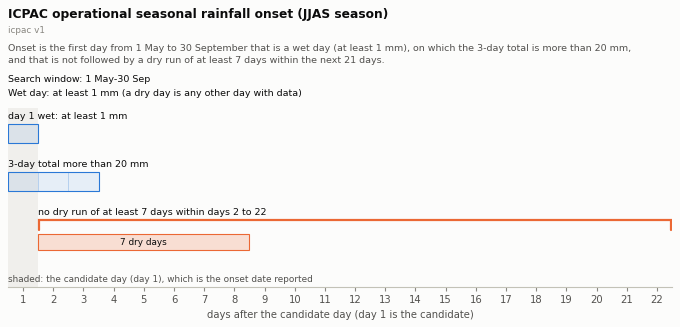

In [5]:
from hcwf.onset.viz.schematic import schematic

schematic(defn)

**One explained onset.** `trace_observed` re-runs the search for one cell and year and records every candidate day and why it passed or failed, then `explain` prints it and `anatomy_plot` draws it (cell 9.0 N, 38.75 E, season 2020). The CLI twin is `hcwf-run onset explain`.

ICPAC operational seasonal rainfall onset (JJAS season) (icpac v1)
Place: lat 9, lon 38.75
Season: main 2020
Rule: Onset is the first day from 1 May to 30 September that is a wet day (at least 1 mm), on which the 3-day total is more than 20 mm, and that is not followed by a dry run of at least 7 days within the next 21 days.
Wet day: at least 1 mm

Candidates (search window 1 May - 30 Sep 2020; 20 evaluated before the decision):
  1-2 May    ✗ 2 days: followed by a dry run of 11 days (5-15 May)
  3-4 May    ✗ 2 days: 3-day total 4.9-10.9 mm, needs more than 20 mm
  5-15 May   ✗ 11 days: day 1 not wet
  16-18 May  ✗ 3 days: 3-day total 3.3-4.9 mm, needs more than 20 mm
  19 May     ✗ day 1 not wet (0.7 mm, wet needs at least 1 mm)
  20 May     ✓ wet day; 3-day total 22.2 mm (more than 20 mm); no dry run of at least 7 days within 21 May - 10 Jun

Result: ONSET on 20 May 2020


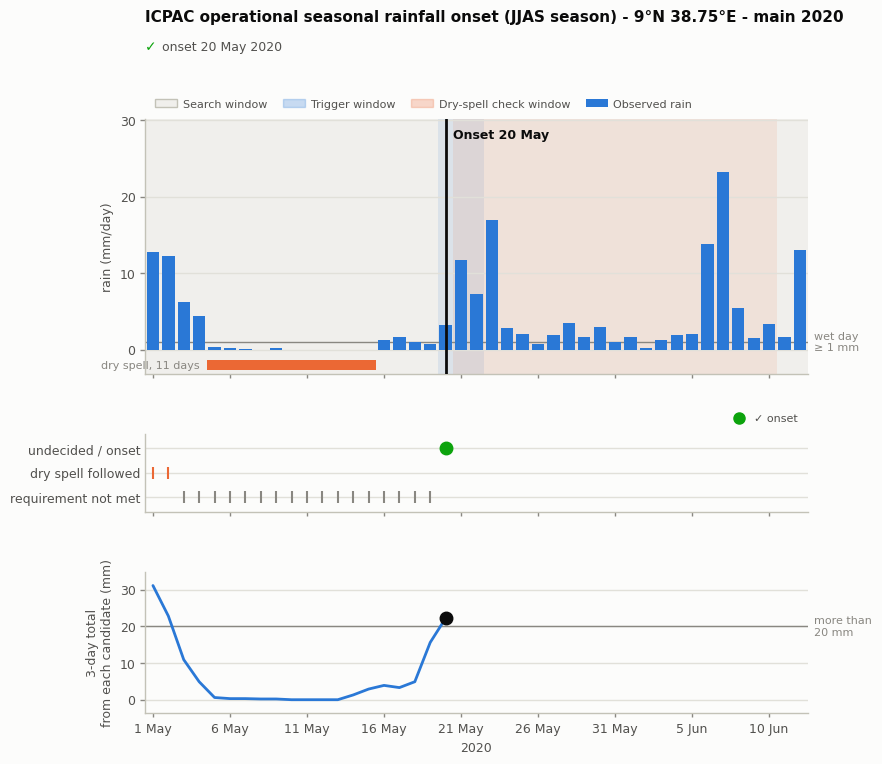

In [6]:
from hcwf.onset import climatology, explain
from hcwf.onset.ingest import ingest
from hcwf.onset.model import DerivedSeasons
from hcwf.onset.viz.anatomy import anatomy_plot

lat, lon, year = 9.0, 38.75, 2020
obs = xr.open_zarr(OBS)
rain_da = next(iter(obs.data_vars.values()))
lat_dim = next(d for d in rain_da.dims if d.lower().startswith("lat"))
lon_dim = next(d for d in rain_da.dims if d.lower().startswith("lon"))
time_dim = next(d for d in rain_da.dims if d.lower() == "time")
first, last = region.climatology_years
# a small box around the cell and the climatology years, which is all the thresholds need
near = rain_da.isel({lat_dim: np.flatnonzero(abs(rain_da[lat_dim] - lat) <= 1.0), lon_dim: np.flatnonzero(abs(rain_da[lon_dim] - lon) <= 1.0)})
rain = ingest(near.sel({time_dim: slice(f"{first}-01-01", f"{last}-12-31")}).load(), day_boundary=region.day_boundary, units="mm")
thresholds = climatology.compute_thresholds(defn, rain, region.climatology_years) if defn.thresholds else None
seasons = climatology.harmonic_seasons(rain, region.climatology_years) if isinstance(defn.seasons, DerivedSeasons) else None
anatomy = explain.trace_observed(defn, rain, lat=lat, lon=lon, year=year, thresholds=thresholds, season_climatology=seasons)
print(explain.explain(anatomy))
anatomy_plot(anatomy)

## 4. Run the benchmarks
`hcwf.run(cfg)` returns a result object. With `write=True` it also writes the run folder exactly as `hcwf-run` does (scores, figures, resolved config); `overwrite=True` makes the notebook re-runnable. Without `write` nothing touches the disk.

**Deterministic**: one onset forecast per model and issue date, scored by onset error (MAE, days), false-alarm rate and miss rate, against the climatology.

In [7]:
det = hcwf.run(cfg, write=True, overwrite=True, quiet=True)
plt.close("all")   # the run also drew its figures to files; keep them out of the notebook
print("run folder:", det.folder)

run folder: runs/ethiopia_icpac_2015-2024_d2bc


**Probabilistic**: the 26 members of AIFS_ENS give onset probabilities for each lead bin, scored by Brier and ranked-probability skill scores (against the climatology reference), AUC and reliability.

In [8]:
cfg_ens = copy.deepcopy(cfg)
cfg_ens["models"] = [{"name": "AIFS_ENS", "path": str(MODELS / "AIFS_ENS_v2.zarr"), "lead_label": cfg["models"][0]["lead_label"]}]
cfg_ens["evaluation"]["probabilistic"] = True
ens = hcwf.run(cfg_ens, write=True, overwrite=True, quiet=True)
plt.close("all")
print("run folder:", ens.folder)

run folder: runs/ethiopia_icpac_2015-2024_574d


## 5. Results as objects
`result.scores` holds pandas and xarray objects: for a deterministic run a summary table and one spatial Dataset per (model, window); for an ensemble run the `overall` and `binned` skill tables. `result.observed` holds the observed onset dates (year, lat, lon).

In [9]:
summary = det.scores["summary"]
display(summary.round(2))
spatial = det.scores["spatial"][("AIFS", "1-15")]
print(list(det.scores["spatial"]))
spatial

,model,window,mean_mae,false_alarm_rate,miss_rate
0,AIFS,1-15,15.89,0.29,0.59
1,AIFS,16-29,13.46,0.23,0.58
2,GraphCast,1-15,19.91,0.35,0.47
3,GraphCast,16-29,10.99,0.13,0.50
4,climatology,1-15,21.71,0.46,0.59
5,climatology,16-29,27.74,0.28,0.46


[('AIFS', '1-15'), ('AIFS', '16-29'), ('GraphCast', '1-15'), ('GraphCast', '16-29'), ('climatology', '1-15'), ('climatology', '16-29')]


<xarray.Dataset> Size: 335kB
Dimensions:           (lat: 49, lon: 61)
Coordinates:
  * lat               (lat) float32 196B 3.0 3.25 3.5 3.75 ... 14.5 14.75 15.0
  * lon               (lon) float32 244B 33.0 33.25 33.5 ... 47.5 47.75 48.0
Data variables: (12/14)
    false_alarm_rate  (lat, lon) float64 24kB nan nan nan nan ... nan nan nan
    miss_rate         (lat, lon) float64 24kB nan nan nan nan ... nan nan nan
    mean_mae          (lat, lon) float64 24kB nan nan nan nan ... nan nan nan
    mae_2015          (lat, lon) float64 24kB nan nan nan nan ... nan nan nan
    mae_2016          (lat, lon) float64 24kB nan nan nan nan ... nan nan nan
    mae_2017          (lat, lon) float64 24kB nan nan nan nan ... nan nan nan
    ...                ...
    mae_2020          (lat, lon) float64 24kB nan nan nan nan ... nan nan nan
    mae_2021          (lat, lon) float64 24kB nan nan nan nan ... nan nan nan
    mae_2022          (lat, lon) float64 24kB nan nan nan nan ... nan nan nan
    mae_2023          (lat, lon) float64 24kB nan nan nan nan ... nan nan nan
    mae_2024          (lat, lon) float64 24kB nan nan nan nan ... nan nan nan
    n_back_dated      (lat, lon) float64 24kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0

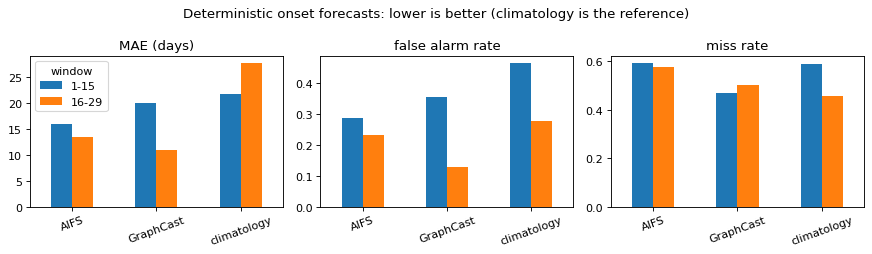

In [10]:
metrics = summary.set_index(["model", "window"])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, column, label in zip(axes, ["mean_mae", "false_alarm_rate", "miss_rate"], ["MAE (days)", "false alarm rate", "miss rate"]):
    metrics[column].unstack("window").plot.bar(ax=ax, rot=20, legend=ax is axes[0])
    ax.set_title(label); ax.set_xlabel("")
fig.suptitle("Deterministic onset forecasts: lower is better (climatology is the reference)")
fig.tight_layout()
plt.show()

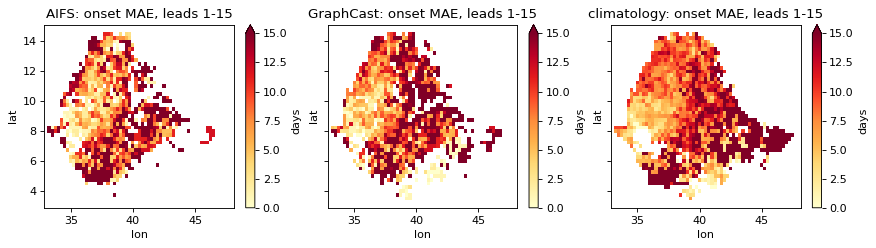

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, model in zip(axes, ["AIFS", "GraphCast", "climatology"]):
    det.scores["spatial"][(model, "1-15")]["mean_mae"].plot(ax=ax, cmap="YlOrRd", vmin=0, vmax=15, cbar_kwargs={"label": "days"})
    ax.set_title(f"{model}: onset MAE, leads 1-15")
fig.tight_layout()
plt.show()

Probabilistic skill tables (positive skill beats the climatology; AUC above `AUC_ref` beats it too):

,model,window,Fair_Brier_Score,Fair_Brier_Skill_Score,Fair_RPS,Fair_RPS_Skill_Score,AUC,AUC_ref,back_dated_member_share
0,AIFS_ENS,1-15,0.087,0.088,0.417,0.165,0.741,0.676,0.203
1,AIFS_ENS,16-29,0.057,-0.028,0.330,-0.064,0.657,0.671,0.203


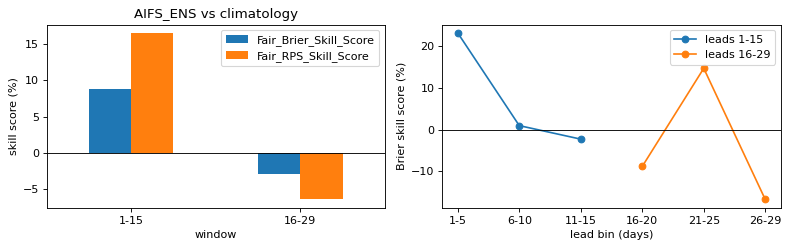

In [12]:
overall = ens.scores["overall"]
display(overall.round(3))
binned = ens.scores["binned"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
(overall.set_index("window")[["Fair_Brier_Skill_Score", "Fair_RPS_Skill_Score"]] * 100).plot.bar(ax=axes[0], rot=0)
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_ylabel("skill score (%)"); axes[0].set_title("AIFS_ENS vs climatology")
for window, part in binned.groupby("window"):
    axes[1].plot(part["clean_bins"], part["Fair_Brier_Skill_Score"] * 100, "o-", label=f"leads {window}")
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_ylabel("Brier skill score (%)"); axes[1].set_xlabel("lead bin (days)"); axes[1].legend()
fig.tight_layout()
plt.show()

**The standard figures** are written to the run folder's `figures/` (skill heatmaps and bars, reliability diagram, spatial maps); here they are loaded back from there.

spatial_metrics_AIFS_1-15.png


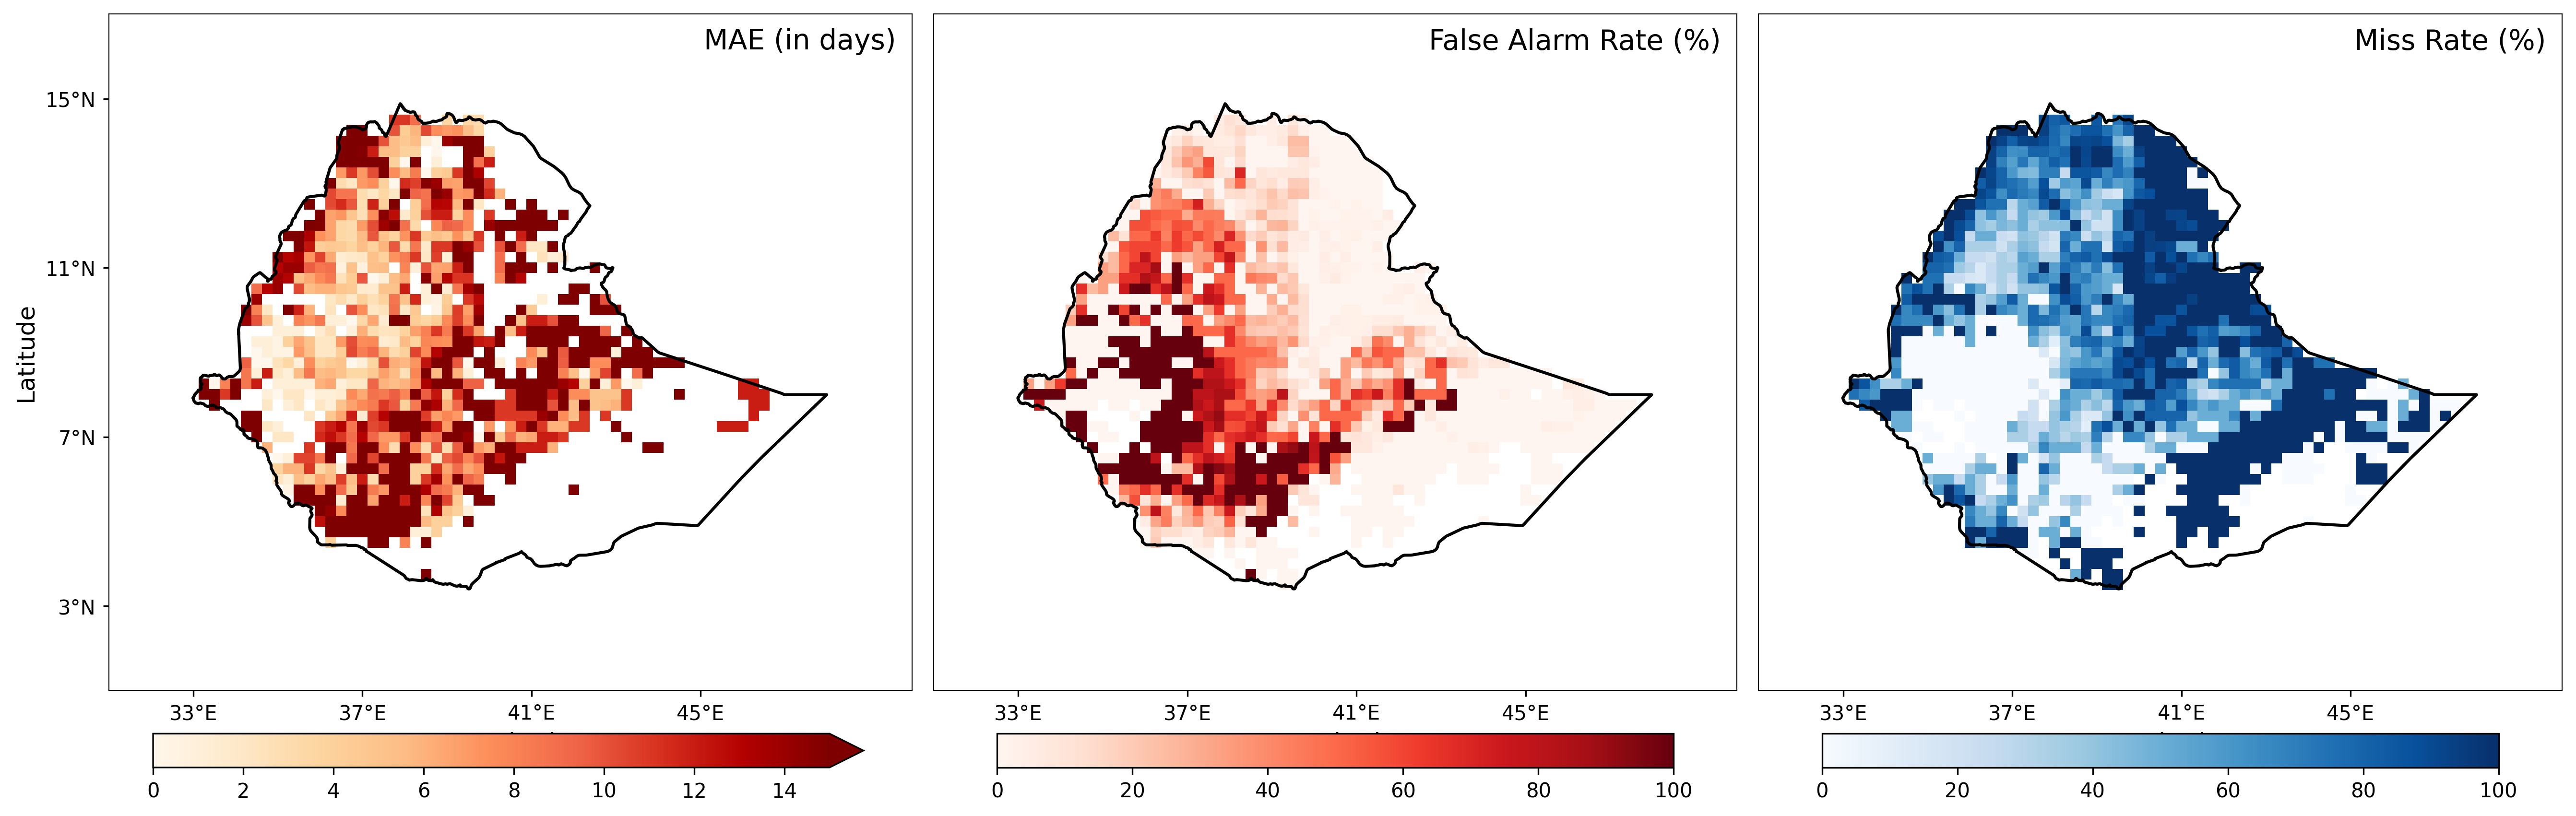

panel_portrait_mae_far_mr_AIFS_29day.png


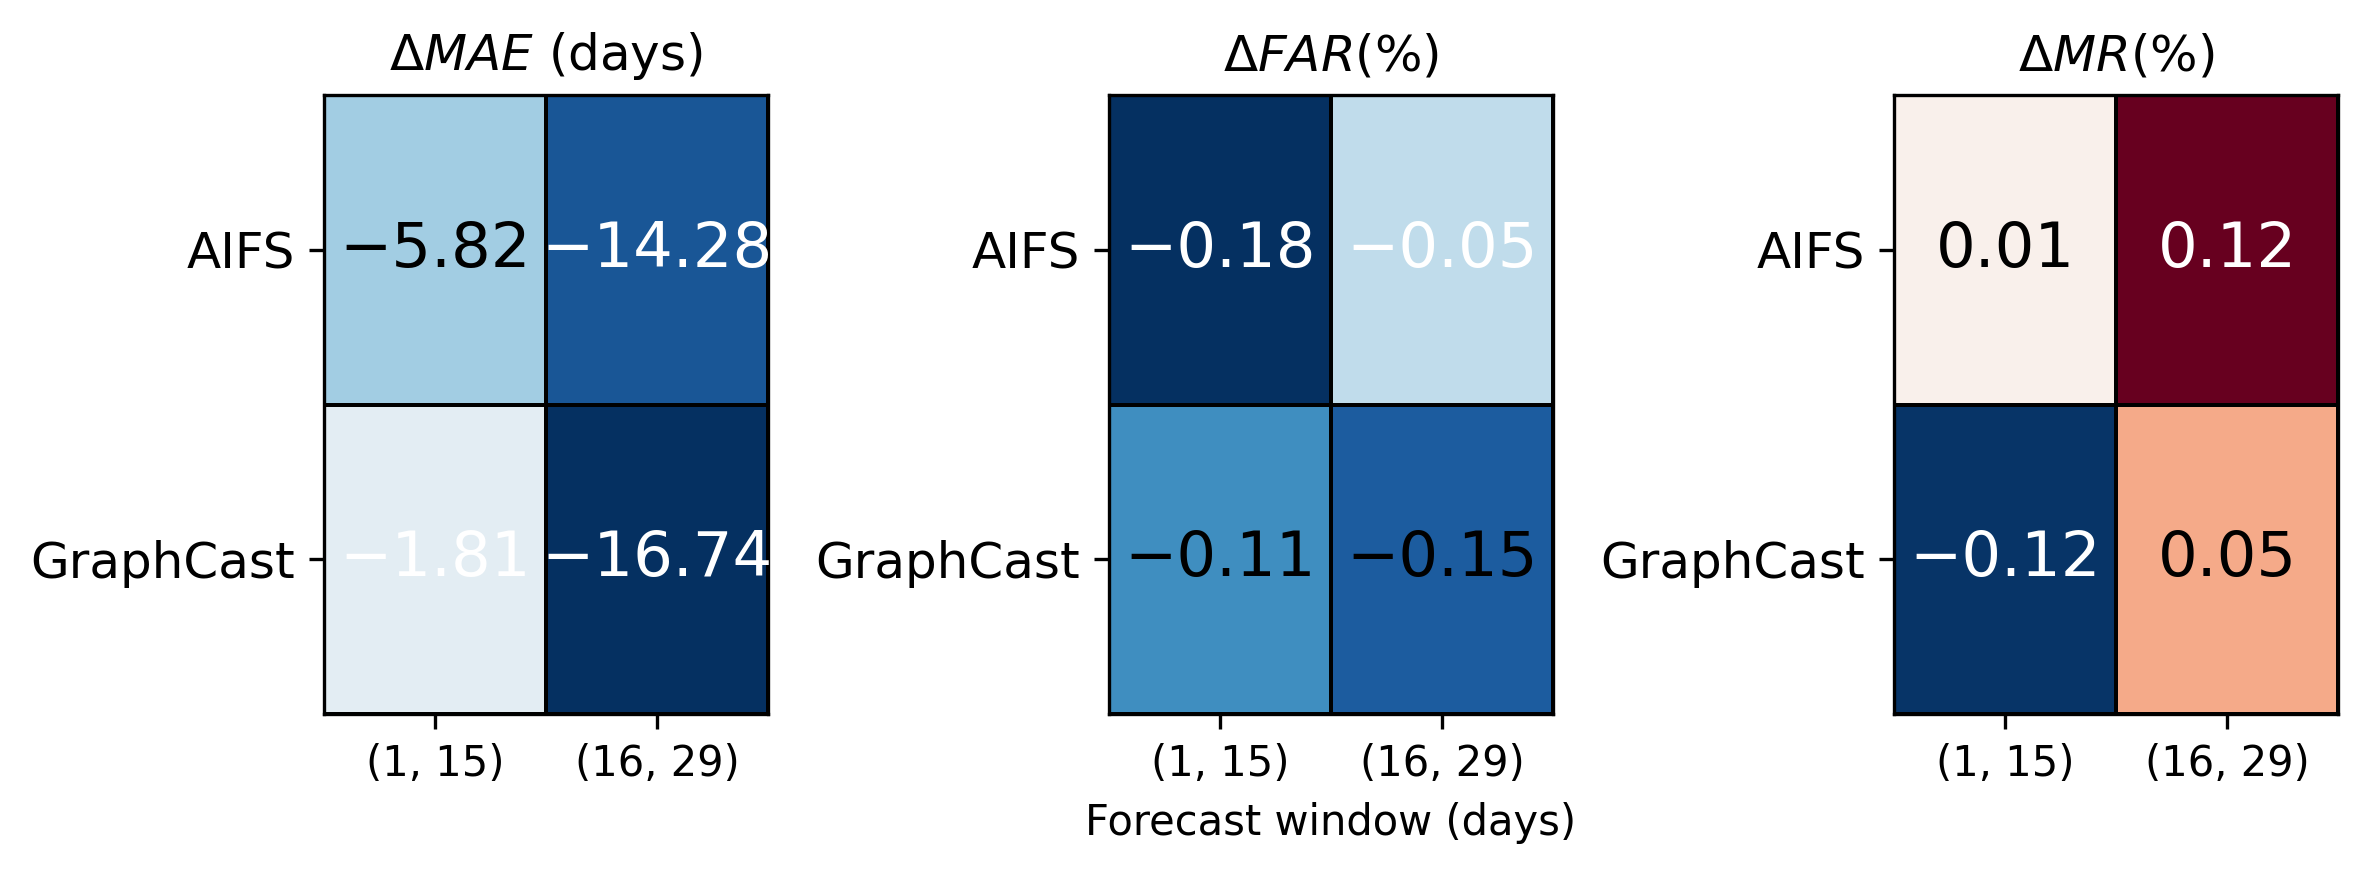

In [13]:
show(det.folder / "figures", "spatial_metrics_AIFS_1-15.png", width=900)
show(det.folder / "figures", "panel_portrait_mae_far_mr_*.png", width=520)

skill_scores_heatmap_AIFS_ENS_1-15.png


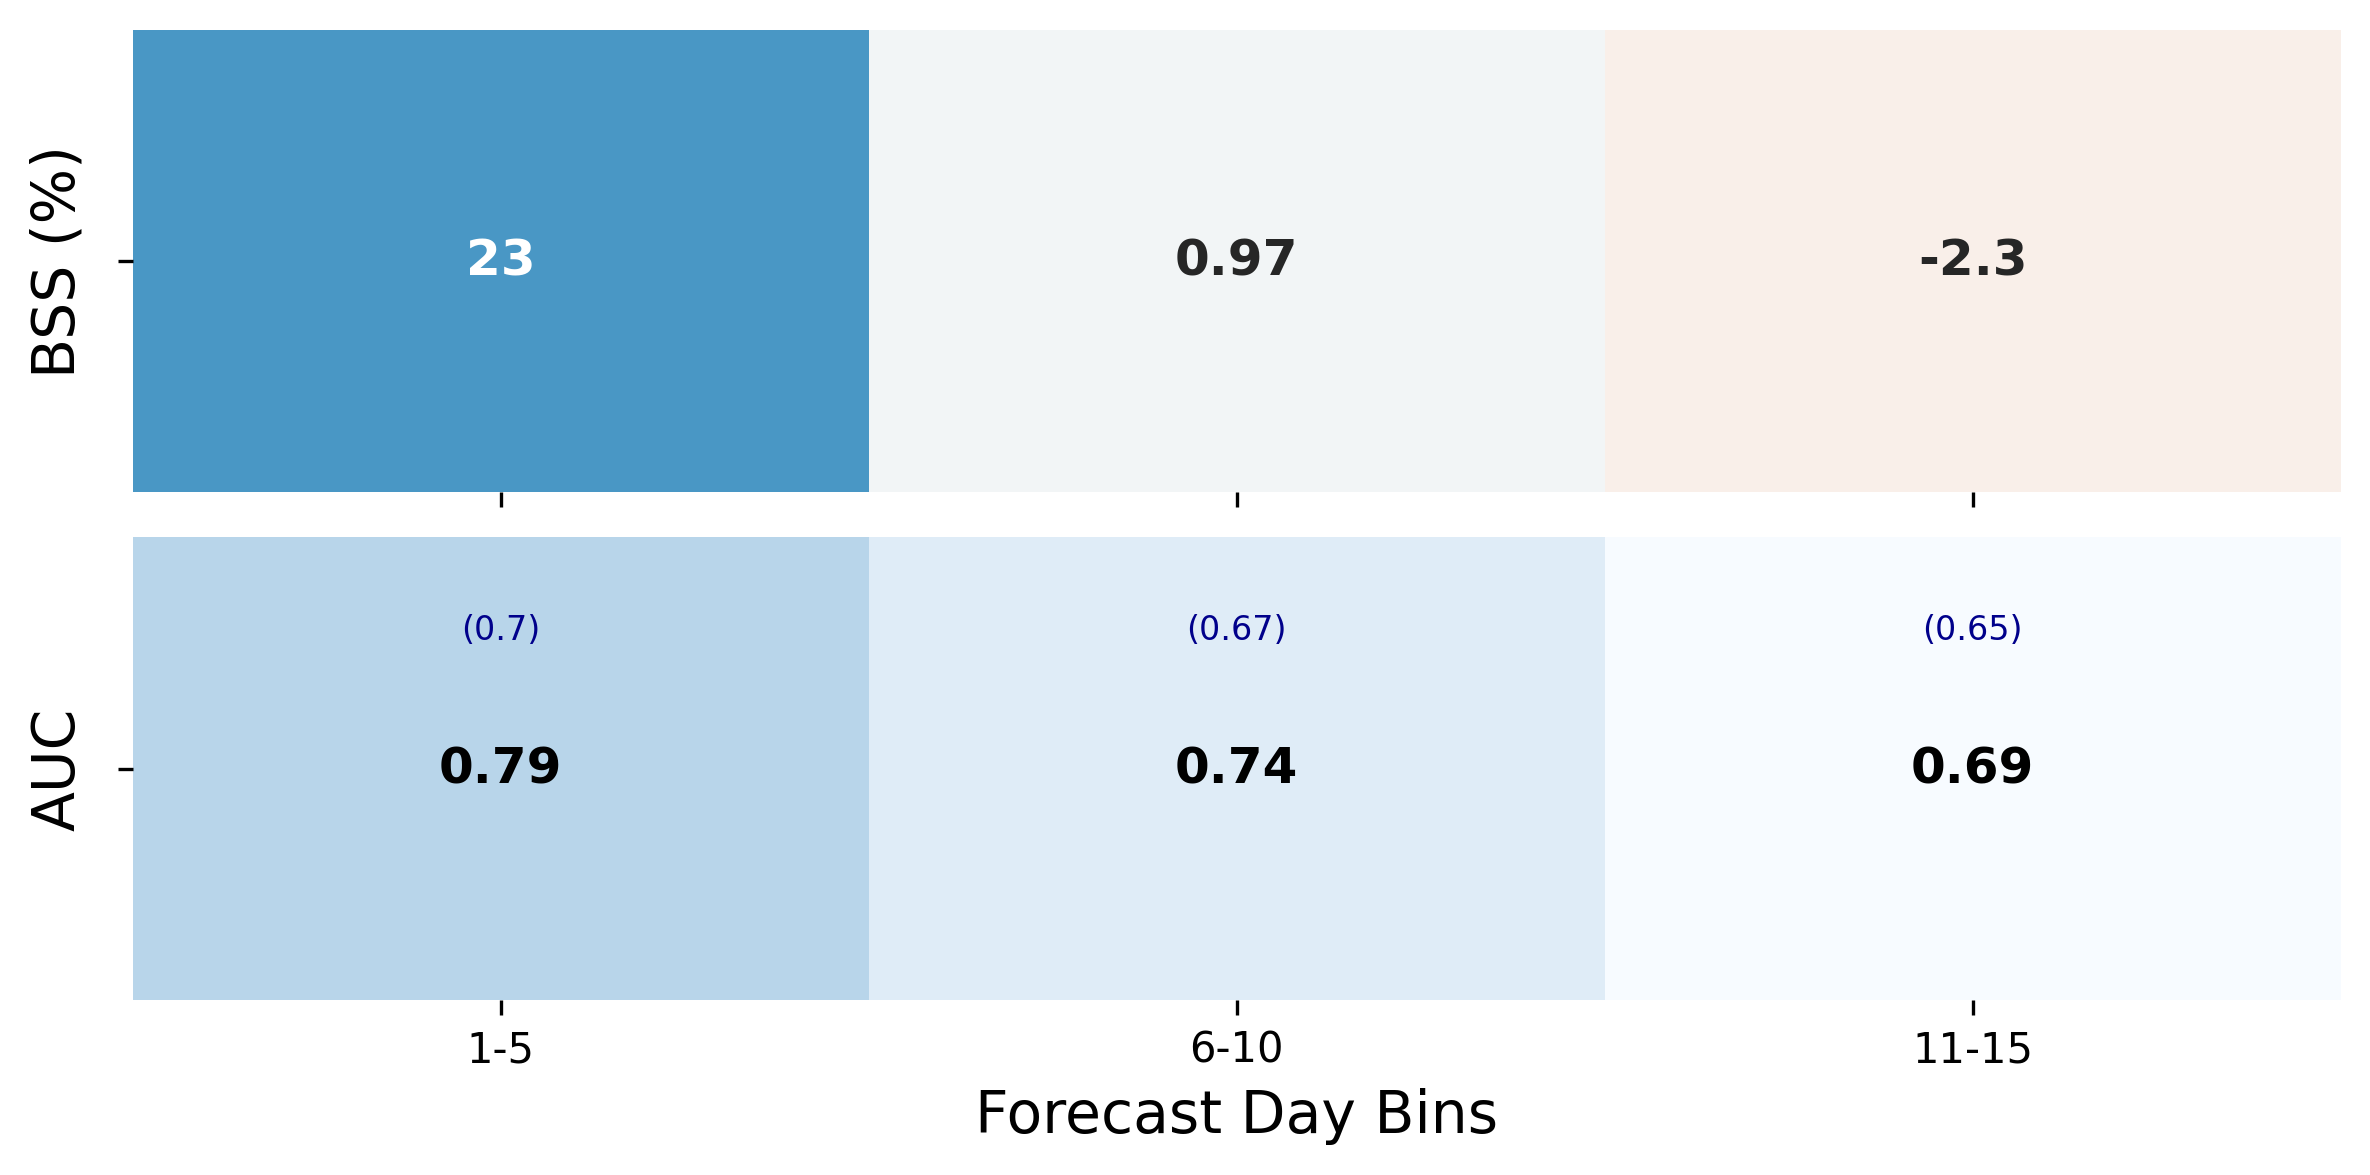

reliability_AIFS_ENS_1-15.png


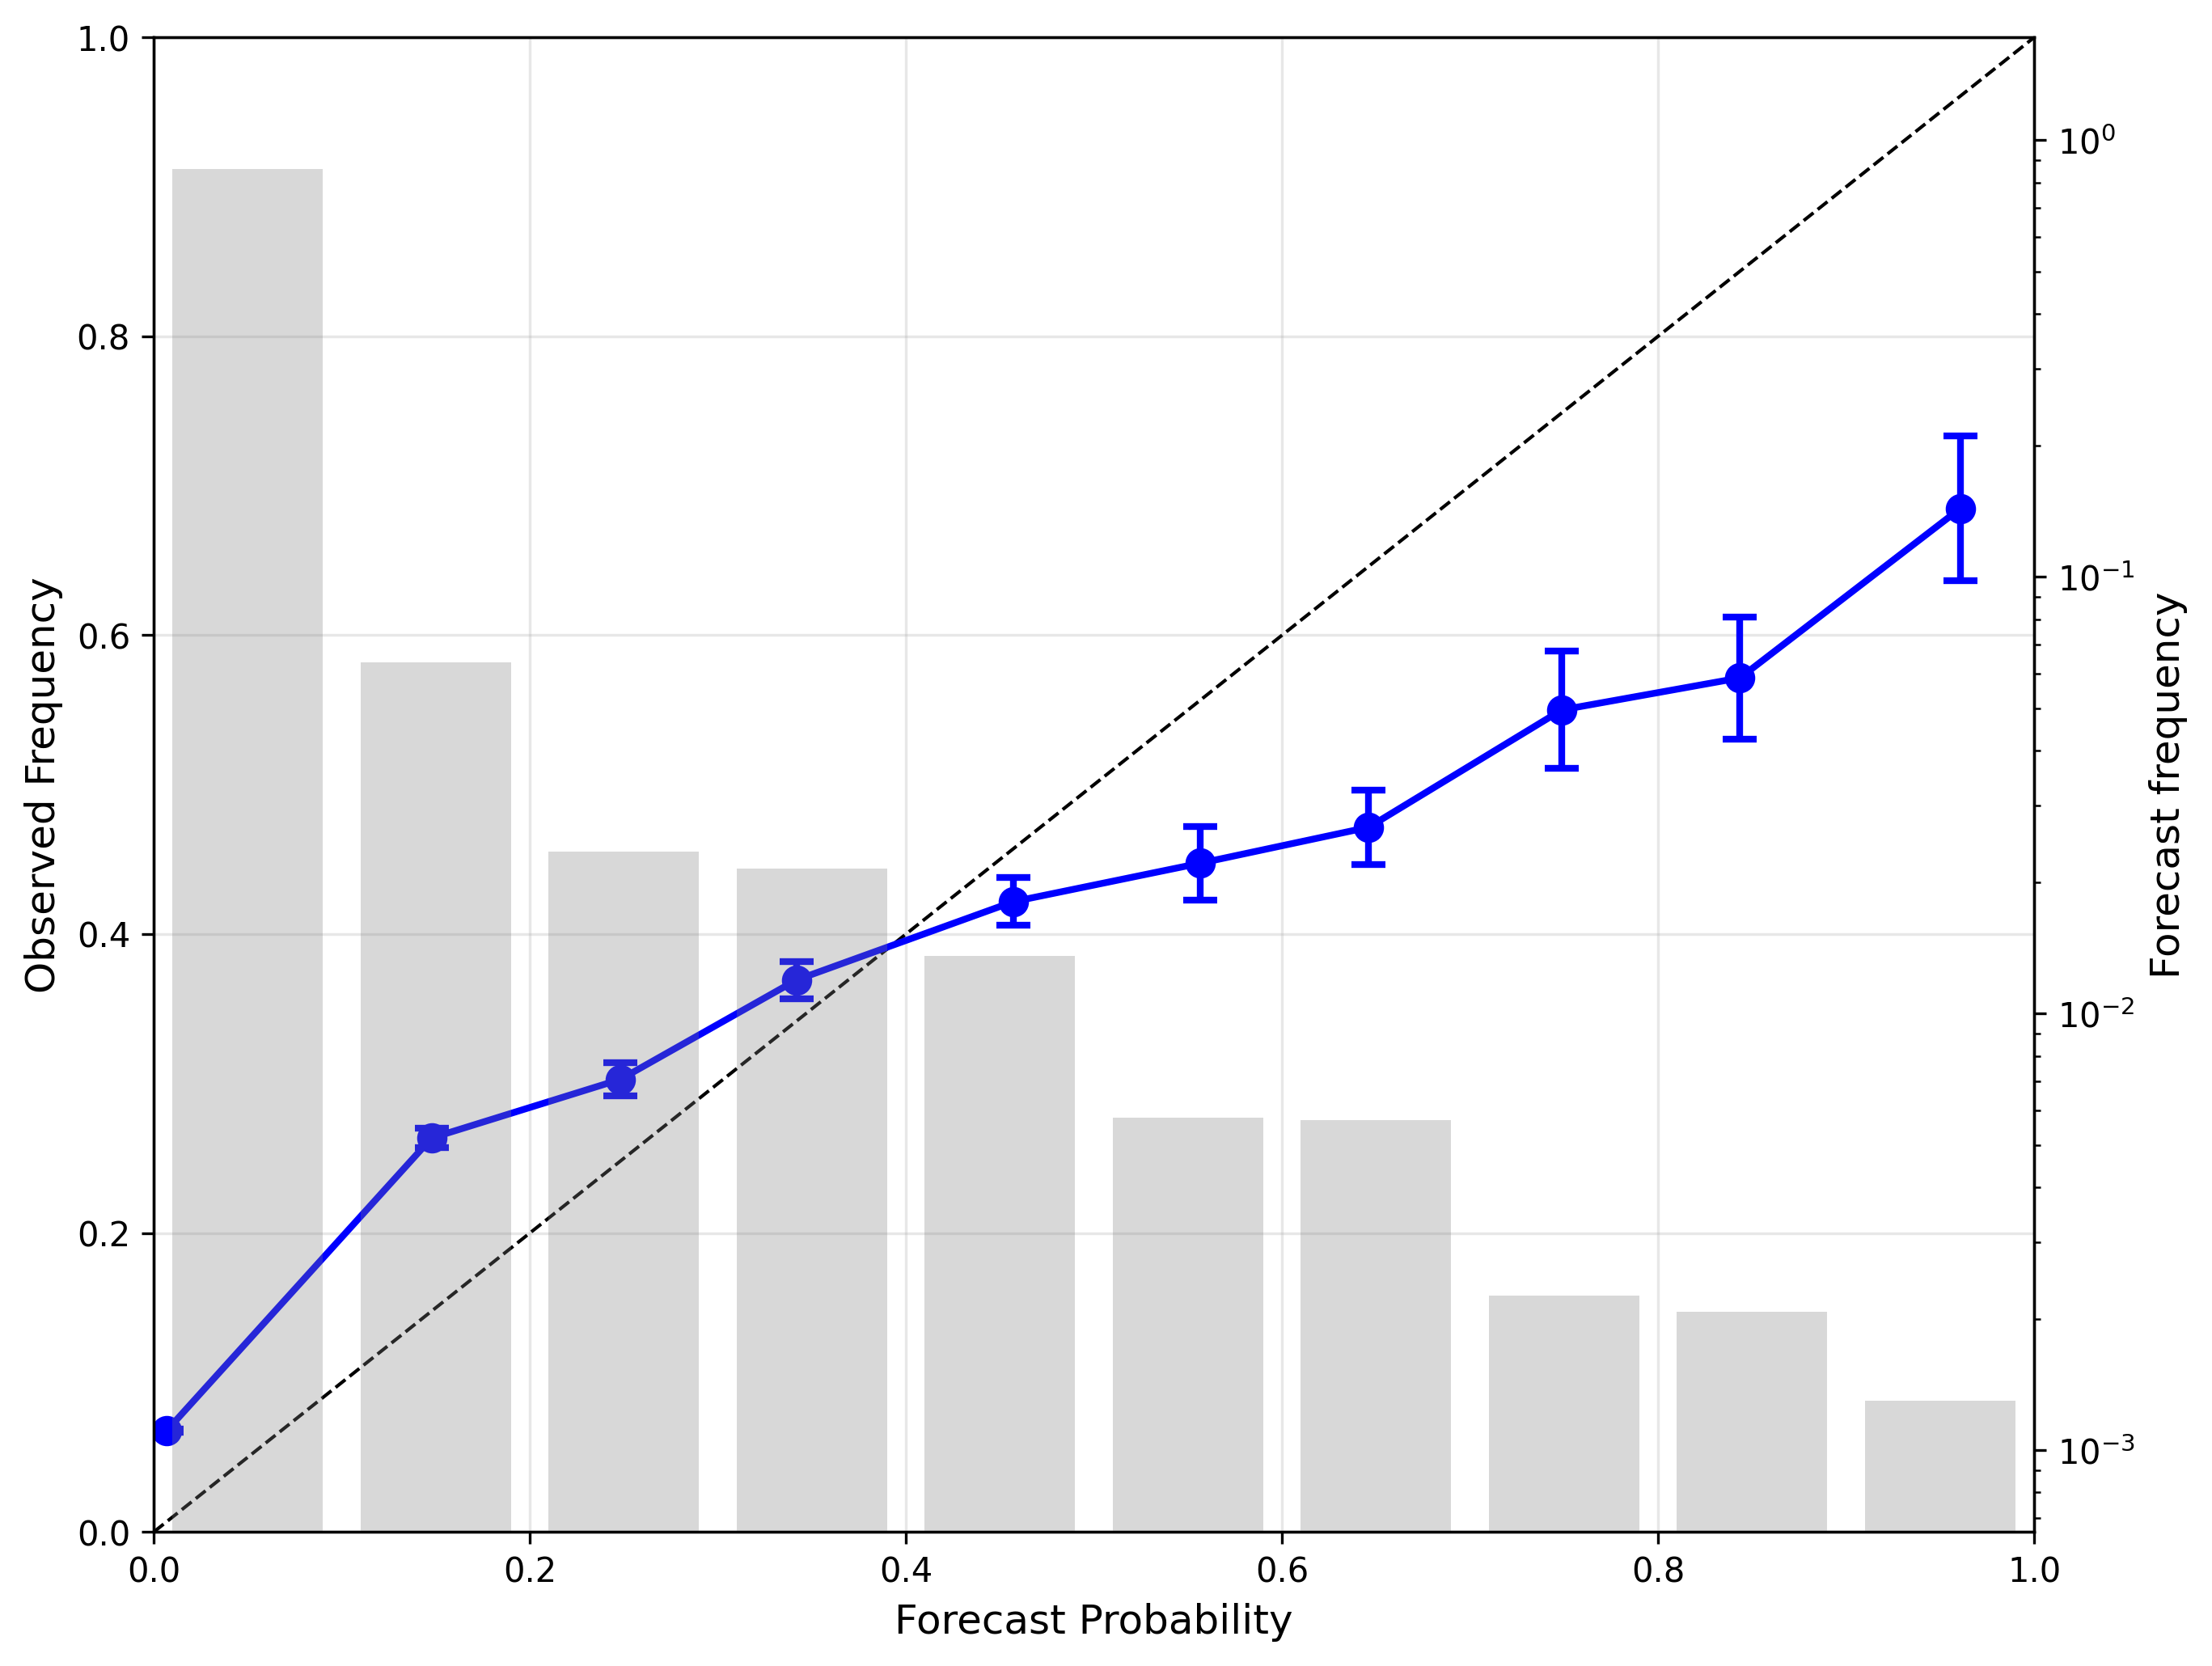

panel_bar_BSS_RPSS_AUC_1-15.png


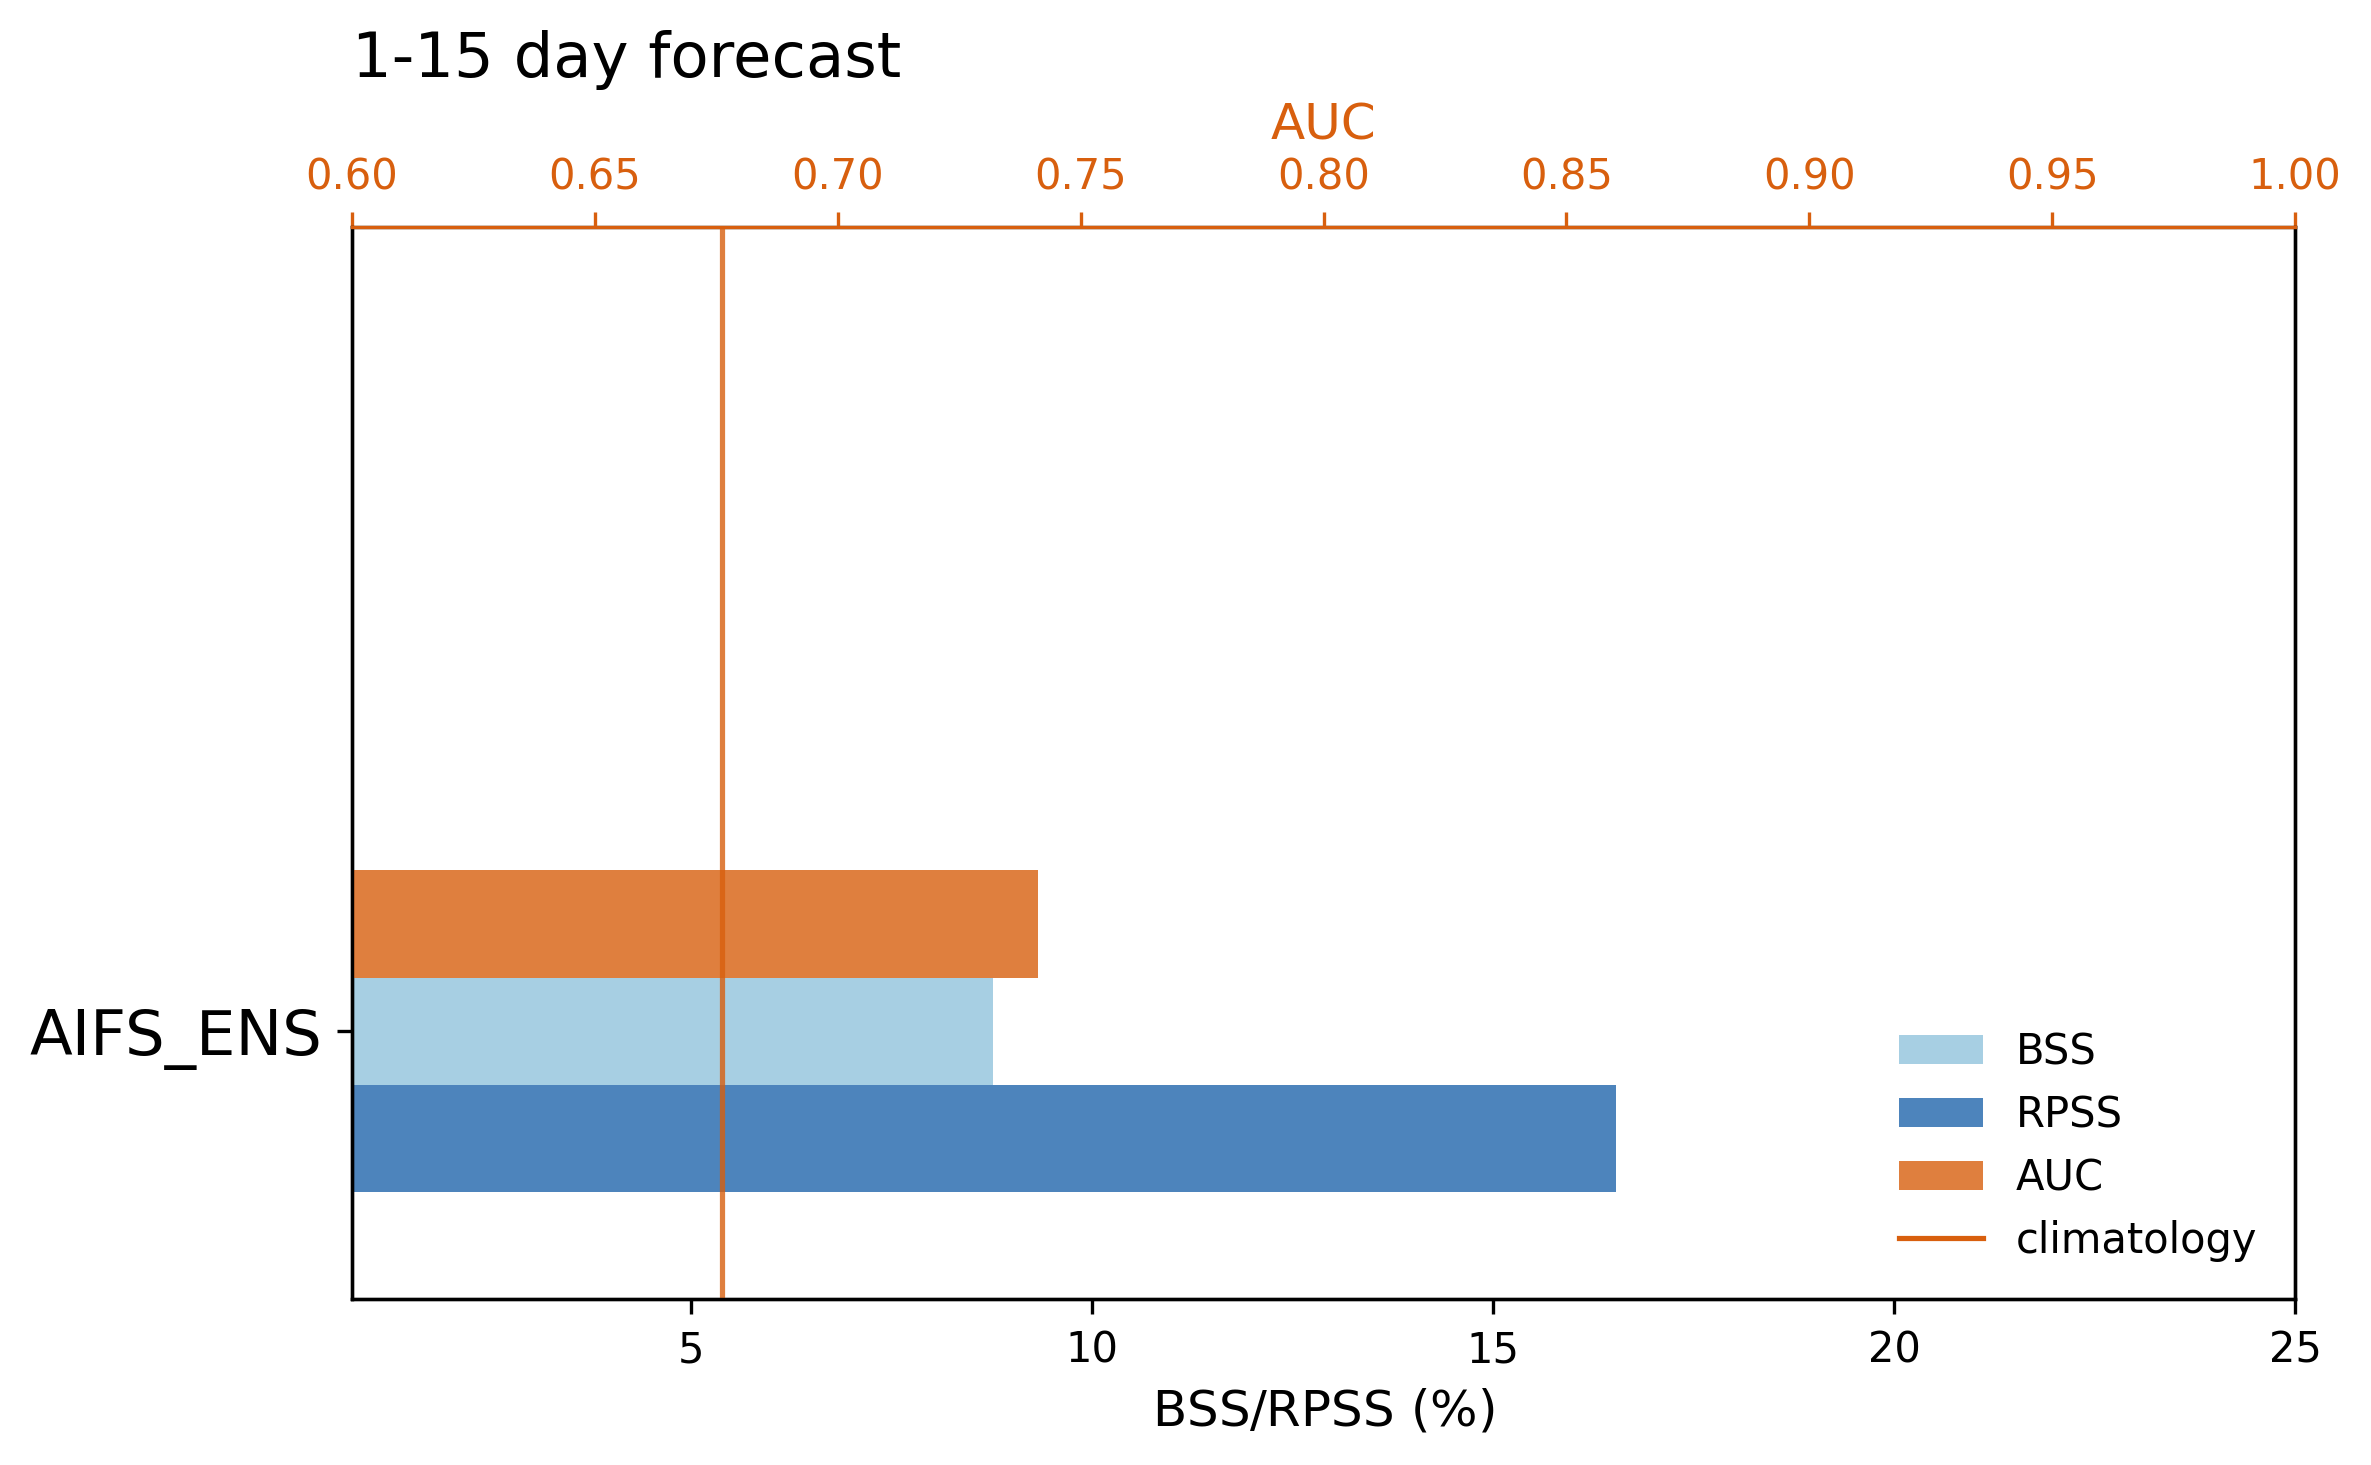

In [14]:
show(ens.folder / "figures", "skill_scores_heatmap_AIFS_ENS_1-15.png", width=520)
show(ens.folder / "figures", "reliability_AIFS_ENS_1-15.png", width=520)
show(ens.folder / "figures", "panel_bar_BSS_RPSS_AUC_1-15.png", width=520)

## 6. What else
**Units.** By default scores are per grid cell. A `units:` section scores on polygons instead (admin units, catchments): rain is area-averaged onto each polygon, onsets are detected and scored per polygon, and results come per `unit`.

The polygon run below reads the same zarr stores as the runs above (a shorter climatology, 2010-2024, and the forecasts of 2019-2021, keep it quick).

In [15]:
import geopandas as gpd
from shapely.geometry import box

# no admin shapefile ships for this region, so make 2-degree tiles to show the interface (use your ADM1/ADM2 file instead)
tiles = gpd.GeoDataFrame(
    {"ID": [f"T{i}{j}" for i in range(6) for j in range(7)]},
    geometry=[box(33 + 2 * j, 3 + 2 * i, 35 + 2 * j, 5 + 2 * i) for i in range(6) for j in range(7)], crs="EPSG:4326")
Path("runs").mkdir(exist_ok=True)
tiles.to_file("runs/tiles.geojson", driver="GeoJSON")

cfg_units = copy.deepcopy(cfg)
cfg_units["models"] = cfg["models"][:1]
cfg_units["evaluation"].update(start_date=[2019, 5, 1], end_date=[2021, 8, 31], start_year_clim=2010, end_year_clim=2024)
cfg_units["units"] = {"shapefile": "runs/tiles.geojson", "unit_id_col": "ID"}
cfg_units["onset"] = {**cfg["onset"], "threshold_years": [2010, 2024]}

In [16]:
by_unit = hcwf.run(cfg_units, quiet=True)   # write=False: nothing is written
display(by_unit.scores["summary"].round(2))
by_unit.observed

,model,window,mean_mae,false_alarm_rate,miss_rate
0,AIFS,1-15,10.23,0.17,0.70
1,AIFS,16-29,19.50,0.02,0.71
2,climatology,1-15,10.18,0.43,0.50
3,climatology,16-29,18.01,0.23,0.33


<xarray.Dataset> Size: 7kB
Dimensions:     (year: 15, unit: 42)
Coordinates:
  * year        (year) int64 120B 2010 2011 2012 2013 ... 2021 2022 2023 2024
  * unit        (unit) <U3 504B 'T00' 'T01' 'T02' 'T03' ... 'T54' 'T55' 'T56'
    unit_name   (unit) <U3 504B 'T00' 'T01' 'T02' 'T03' ... 'T54' 'T55' 'T56'
    lat         (unit) float64 336B 4.0 4.0 4.0 4.0 4.0 ... 14.0 14.0 14.0 14.0
    lon         (unit) float64 336B 34.0 36.0 38.0 40.0 ... 40.0 42.0 44.0 46.0
Data variables:
    onset_date  (year, unit) datetime64[ns] 5kB 2010-05-08 2010-05-05 ... NaT
Attributes:
    fingerprint:  obs-bdf39f66ee3c

**Caches and run folders.** Observed onsets are detected once and cached under `runs/.cache/` (keyed by data, definition, thresholds and years), so the second model, a re-run or another reference reuses them; dataset detections are cached per machine. `hcwf-run cache info` lists both; a run folder holds the resolved config (every value with its source), the definition, the log, scores and figures.

In [17]:
subprocess.run([sys.executable, "-m", "hcwf.cli", "cache", "info"], check=False)   # = hcwf-run cache info
print()
for path in sorted(det.folder.rglob("*")):
    if path.is_file() and "figures" not in path.parts[-2:-1]:
        print(path.relative_to(det.folder.parent))
print("figures/:", len(list((det.folder / "figures").glob("*.png"))), "PNG files")

runs/.cache
  observed_onsets         1 entries    639.4 KB  oldest 11m  newest 11m
~/.cache/hcwf
  alignment               2 entries      2.4 KB  oldest 1h  newest 1h
  detect              10472 entries     11.5 MB  oldest 1d  newest 56s
  oracle                 31 entries     30.2 MB  oldest 2h  newest 12m
total 42.4 MB

ethiopia_icpac_2015-2024_d2bc/definition.yaml
ethiopia_icpac_2015-2024_d2bc/run.log
ethiopia_icpac_2015-2024_d2bc/run.yaml
ethiopia_icpac_2015-2024_d2bc/scores/climatology_onset.nc
ethiopia_icpac_2015-2024_d2bc/scores/spatial_AIFS_1-15.nc
ethiopia_icpac_2015-2024_d2bc/scores/spatial_AIFS_16-29.nc
ethiopia_icpac_2015-2024_d2bc/scores/spatial_GraphCast_1-15.nc
ethiopia_icpac_2015-2024_d2bc/scores/spatial_GraphCast_16-29.nc
ethiopia_icpac_2015-2024_d2bc/scores/spatial_climatology_1-15.nc
ethiopia_icpac_2015-2024_d2bc/scores/spatial_climatology_16-29.nc
figures/: 8 PNG files


Next: the blending notebook for this region trains a blend on these forecasts and applies it to a live forecast. Other onset definitions: `hcwf-run onset list`; check a definition's behaviour with `hcwf-run onset describe <id>`.